## Testing our models


### Testing on regular season

Data preprocessing

In [1]:
import joblib
from comet_ml import Experiment
import os
from util.data_aquisition import generate
from util.engineered_data_frame import engineered_data_frame

In [2]:
data = generate(seasons=[2019], play_offs=[False])

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2019-2020


In [3]:
df = engineered_data_frame(data)

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import metrics
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from util.metrics_visualization import generate_four_curves

In [5]:
selected_features = ["Period", "Period_Time_Seconds", "Distance_Net", "Angle", "X_Coordinate", "Speed",
                     "Friendly_Non_Goalies", "Opponent_Non_Goalies", "Shoot_Type"]
df_selected_features = df[selected_features]
df_selected_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)
df_selected_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69217 entries, 0 to 69216
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Period                69217 non-null  int64  
 1   Period_Time_Seconds   69217 non-null  int64  
 2   Distance_Net          69216 non-null  float64
 3   Angle                 69216 non-null  float64
 4   X_Coordinate          69216 non-null  float64
 5   Speed                 68454 non-null  float64
 6   Friendly_Non_Goalies  69217 non-null  int64  
 7   Opponent_Non_Goalies  69217 non-null  int64  
 8   Shoot_Type            69206 non-null  object 
 9   is_goal               69217 non-null  int64  
dtypes: float64(4), int64(5), object(1)
memory usage: 5.3+ MB


/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_28246/2249981398.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_selected_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)


In [6]:
df_selected_features = df_selected_features.dropna()
df_selected_features = df_selected_features[df_selected_features.Speed!=np.inf]

In [7]:
#On doit utiliser le même transformateur que celui qui a été utilisé pour les données d'entrainement (mêmes encodages,
#mêmes moyennes et déviations standard pour la standardisation).
my_transformer = joblib.load("models/selected_features_transformer.joblib")
X_selected = df_selected_features.iloc[:, :-1]
y_selected = df_selected_features.iloc[:, -1]
X_selected = my_transformer.transform(X_selected)
y_selected.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period', 'standard__Period_Time_Seconds',
       'standard__Distance_Net', 'standard__Angle',
       'standard__X_Coordinate', 'standard__Speed',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'remainder__Friendly_Non_Goalies',
       'remainder__Opponent_Non_Goalies'], dtype=object)

In [8]:
features_columns = ['Period_Time_Seconds', 'Period', 'X_Coordinate', 'Y_Coordinate', 'Distance_Net', 'Angle',
                    'Shoot_Type', 'Last_Event_Type', 'Last_Coordinate_X', 'Last_Coordinate_Y',
                    'Time_Between_Events', 'Distance_Last_Event', 'Rebond', 'Delta_Angle', 'Speed',
                    'Powerplay_Since', 'Friendly_Non_Goalies','Opponent_Non_Goalies']

In [9]:
df_all_features = df[features_columns]
df_all_features["is_goal"] = df["Event_Type"].map(lambda x: 1 if x == "Goal" else 0)
df_all_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69217 entries, 0 to 69216
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Period_Time_Seconds   69217 non-null  int64  
 1   Period                69217 non-null  int64  
 2   X_Coordinate          69216 non-null  float64
 3   Y_Coordinate          69216 non-null  float64
 4   Distance_Net          69216 non-null  float64
 5   Angle                 69216 non-null  float64
 6   Shoot_Type            69206 non-null  object 
 7   Last_Event_Type       69217 non-null  object 
 8   Last_Coordinate_X     68459 non-null  float64
 9   Last_Coordinate_Y     68459 non-null  float64
 10  Time_Between_Events   69217 non-null  int64  
 11  Distance_Last_Event   68458 non-null  float64
 12  Rebond                69217 non-null  bool   
 13  Delta_Angle           69215 non-null  float64
 14  Speed                 68454 non-null  float64
 15  Powerplay_Since    

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_28246/126522627.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_all_features["is_goal"] = df["Event_Type"].map(lambda x: 1 if x == "Goal" else 0)


In [10]:
df_all_features = df_all_features.dropna()
df_all_features = df_all_features[df_all_features.Speed != np.inf]
#On doit utiliser le même transformateur que celui qui a été utilisé pour les données d'entrainement (mêmes encodages,
#mêmes moyennes et déviations standard pour la standardisation).
my_transformer = joblib.load("models/all_features_transformer.joblib")
X_all = df_all_features.iloc[:, :-1]
y_all = df_all_features.iloc[:, -1]
X_all = my_transformer.transform(X_all)
y_all.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period_Time_Seconds', 'standard__X_Coordinate',
       'standard__Y_Coordinate', 'standard__Distance_Net',
       'standard__Angle', 'standard__Last_Coordinate_X',
       'standard__Last_Coordinate_Y', 'standard__Time_Between_Events',
       'standard__Distance_Last_Event', 'standard__Delta_Angle',
       'standard__Speed', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'one-hot__Last_Event_Type_Blocked Shot',
       'one-hot__Last_Event_Type_Faceoff',
       'one-hot__Last_Event_Type_Giveaway',
       'one-hot__Last_Event_Type_Goal', 'one-hot__Last_Event_Type_Hit',
       'one-hot__Last_Event_Type_Missed Shot',
       'one-hot__Last_Event_Type_Penalty',
       'one-hot__Last_Event_Type_Shot',
       'one-hot__Last_Event_Type

In [11]:
def my_calibration_scorer(estimator,
                      X,
                      y,
                      n_bins=20
):
    """
    Implements the Expexted Calibration Error
    """

    y_prob = estimator.predict_proba(X)[:,1]

    bins = np.linspace(0.0, 1.0, n_bins + 1)

    binids = np.searchsorted(bins[1:-1], y_prob)

    bin_sums = np.bincount(binids, weights=y_prob, minlength=len(bins))
    bin_true = np.bincount(binids, weights=y, minlength=len(bins))
    bin_total = np.bincount(binids, minlength=len(bins))

    nonzero = bin_total != 0
    prob_true = bin_true[nonzero] / bin_total[nonzero]
    prob_pred = bin_sums[nonzero] / bin_total[nonzero]
    calibration_error = np.sum(np.abs(prob_true - prob_pred) * (bin_total[nonzero] / len(y)))

    return -calibration_error

Logistic regression on distance

In [28]:
model = joblib.load("models/log_reg_dist.joblib")

Accuracy on testing data:  90.71
f1 score: 0.4756514460498627
 ece: 0.08364752117593184


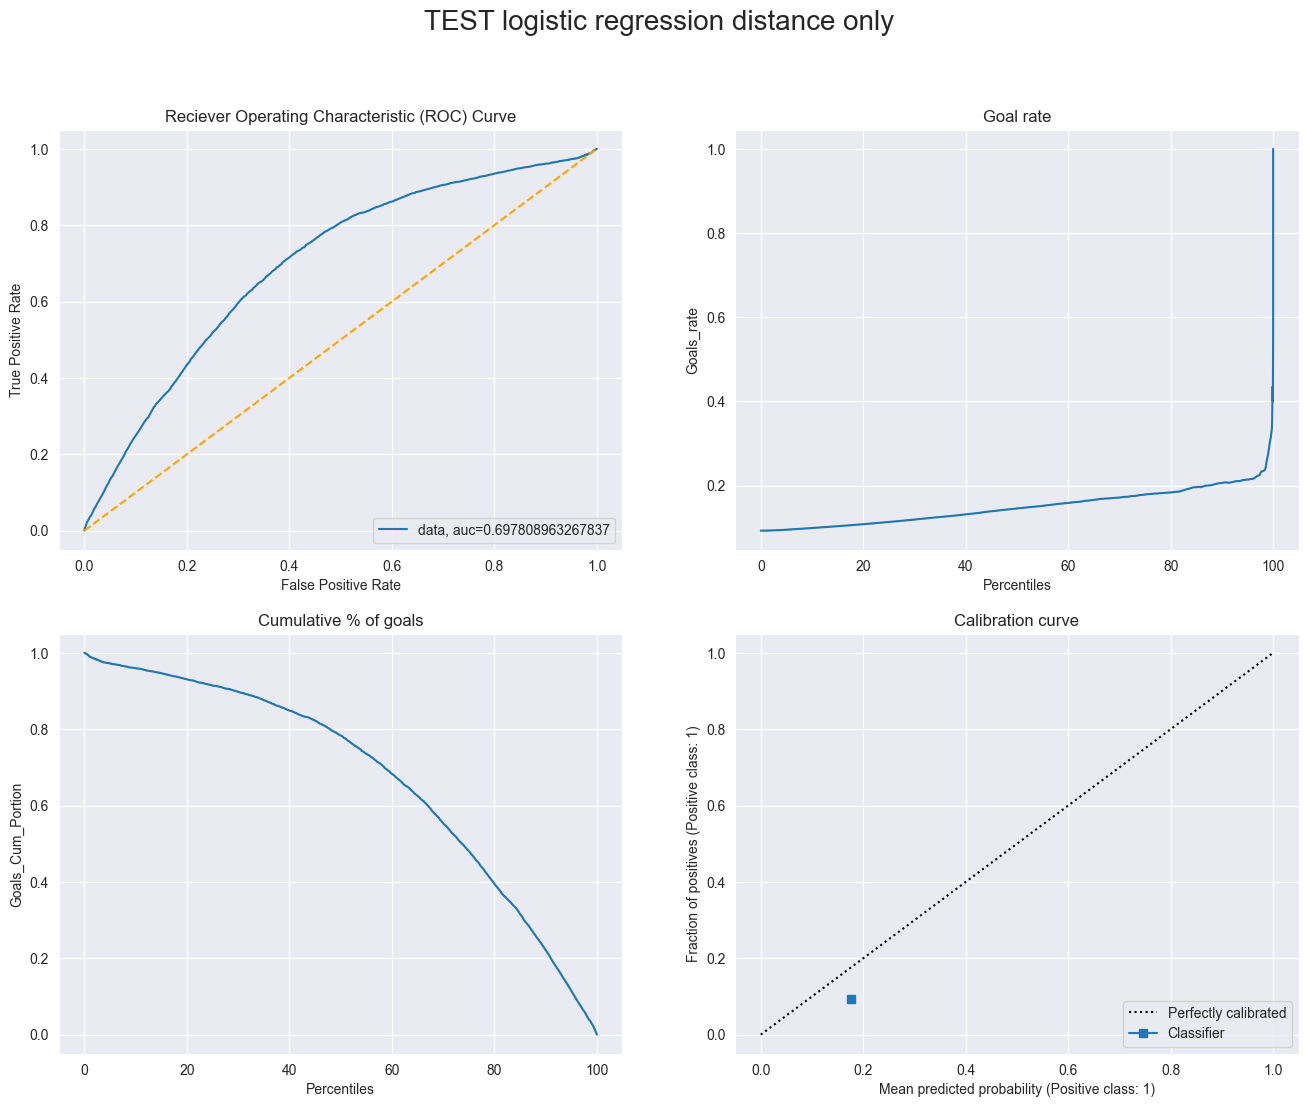

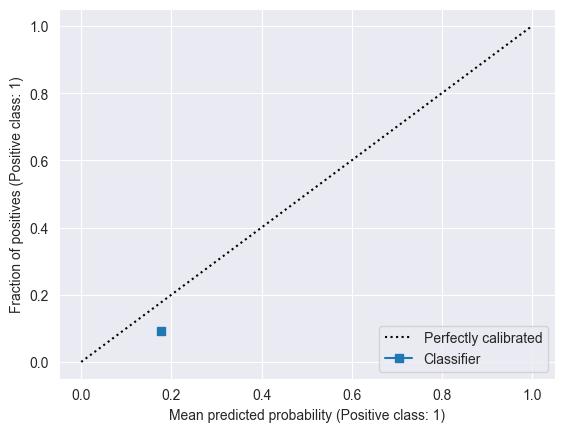

In [29]:
result = model.score(X_selected[:,2].reshape(-1,1),y_selected)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST logistic regression distance only", y_selected, model.predict_proba(X_selected[:,2].reshape(-1,1))[:,1], 20)
f1 = metrics.f1_score(y_selected, model.predict(X_selected[:,2].reshape(-1,1)), average='macro')
ece = -my_calibration_scorer(model, X_selected[:,2].reshape(-1,1), y_selected)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_selected, model.predict_proba(X_selected[:,2].reshape(-1,1))[:,1])

Logistic regression on angle

In [30]:
model = joblib.load("models/log_reg_angle.joblib")

Accuracy on testing data:  90.71
f1 score: 0.4756514460498627
 ece: 0.0007672438836425766


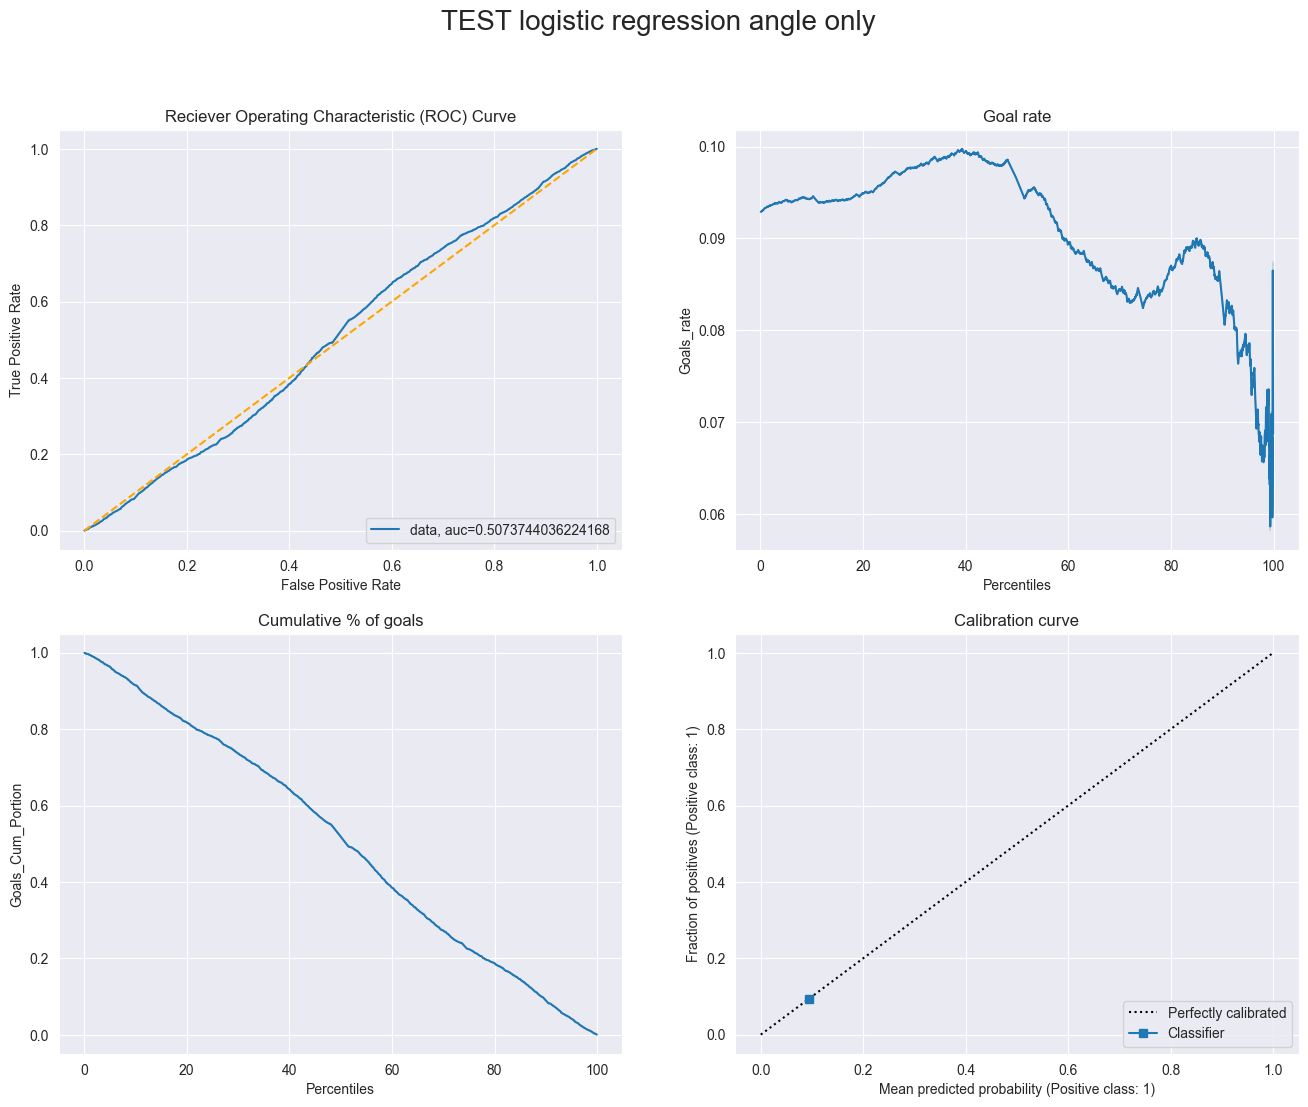

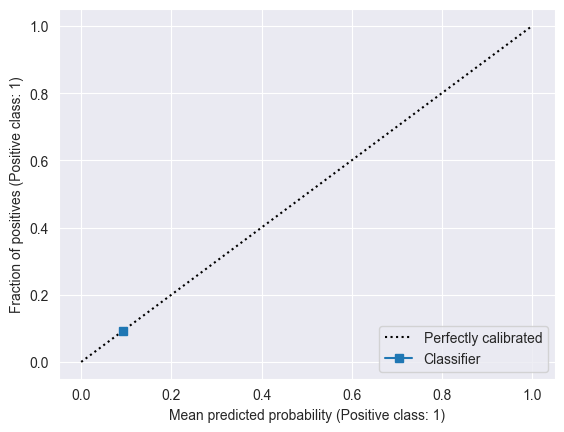

In [31]:
result = model.score(X_selected[:,3].reshape(-1,1),y_selected)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST logistic regression angle only", y_selected, model.predict_proba(X_selected[:,3].reshape(-1,1))[:,1], 20)
f1 = metrics.f1_score(y_selected, model.predict(X_selected[:,3].reshape(-1,1)), average='macro')
ece = -my_calibration_scorer(model, X_selected[:,3].reshape(-1,1), y_selected)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_selected, model.predict_proba(X_selected[:,3].reshape(-1,1))[:,1])

Logistic regression on angle and distance

In [32]:
model = joblib.load("models/log_reg_dist_and_angle.joblib")

Accuracy on testing data:  90.71
f1 score: 0.4756514460498627
 ece: 0.08374224360135389


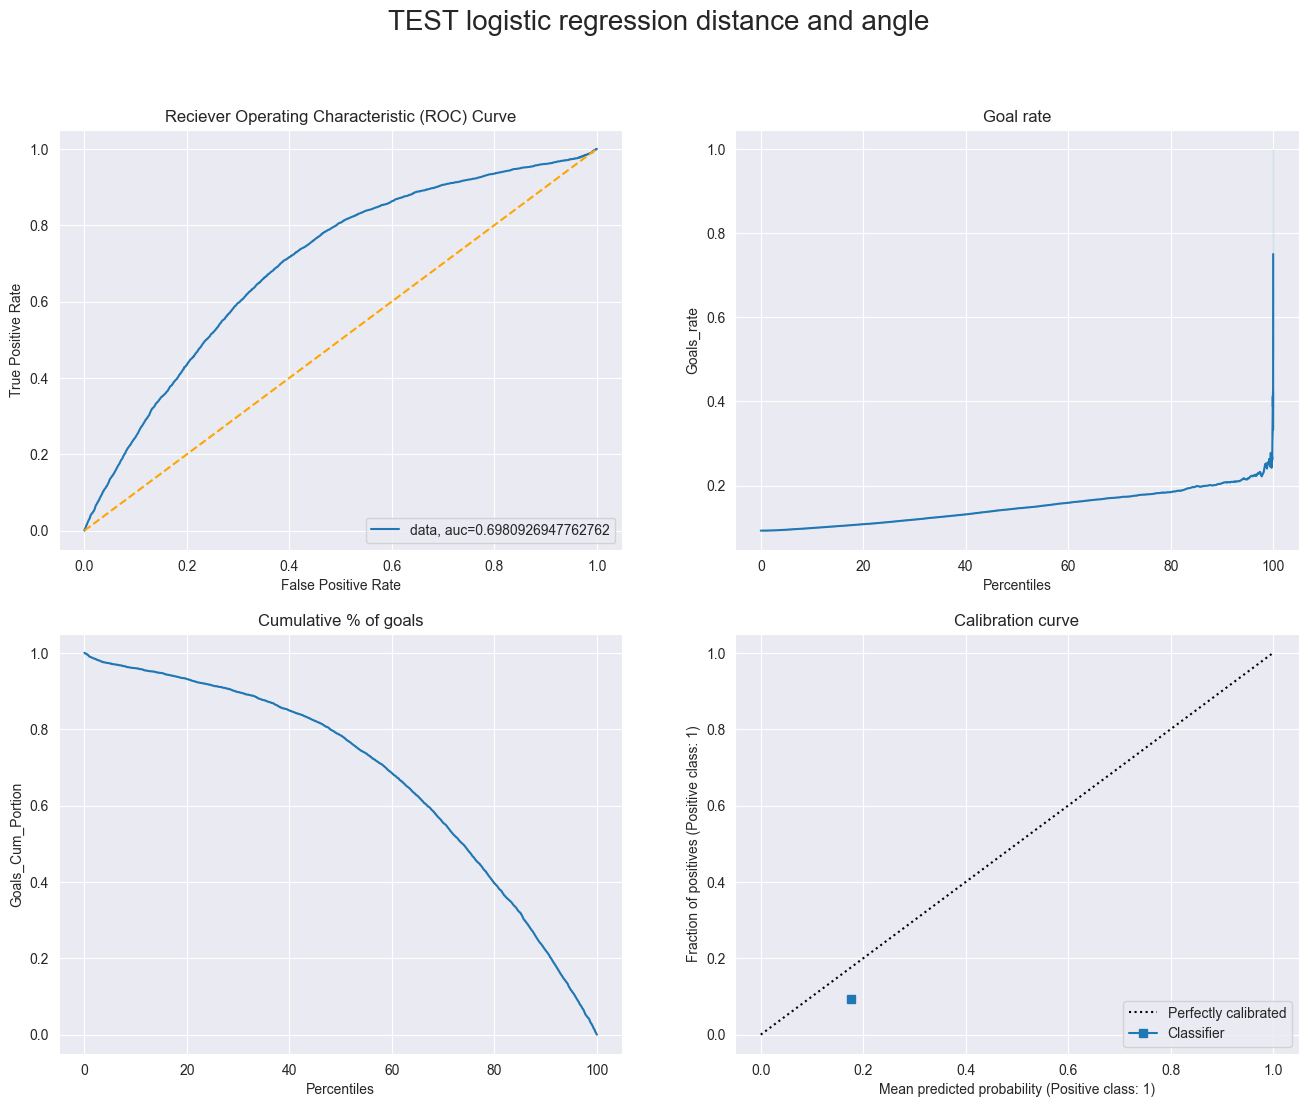

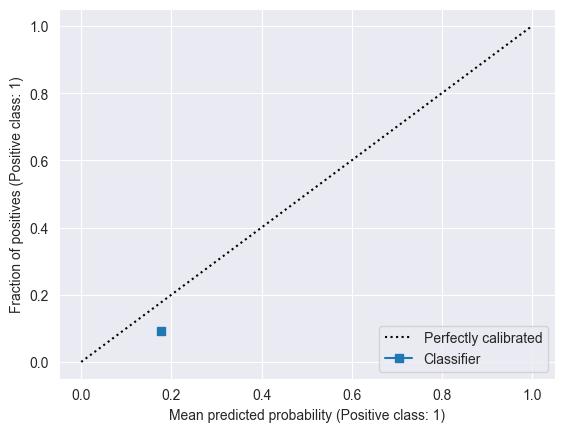

In [33]:
result = model.score(X_selected[:,2:4],y_selected)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST logistic regression distance and angle", y_selected, model.predict_proba(X_selected[:,2:4])[:,1], 20)
f1 = metrics.f1_score(y_selected, model.predict(X_selected[:,2:4]), average='macro')
ece = -my_calibration_scorer(model, X_selected[:,2:4], y_selected)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_selected, model.predict_proba(X_selected[:,2:4])[:,1])

Best XGBOOST model (Part 5, without feature selection)

In [34]:
from xgboost import XGBClassifier

In [35]:
model = XGBClassifier()
model.load_model("models/xgb_tuned_all_features.json")

Accuracy on testing data:  90.79
f1 score: 0.49854745400631423
 ece: 0.0047723075738714486


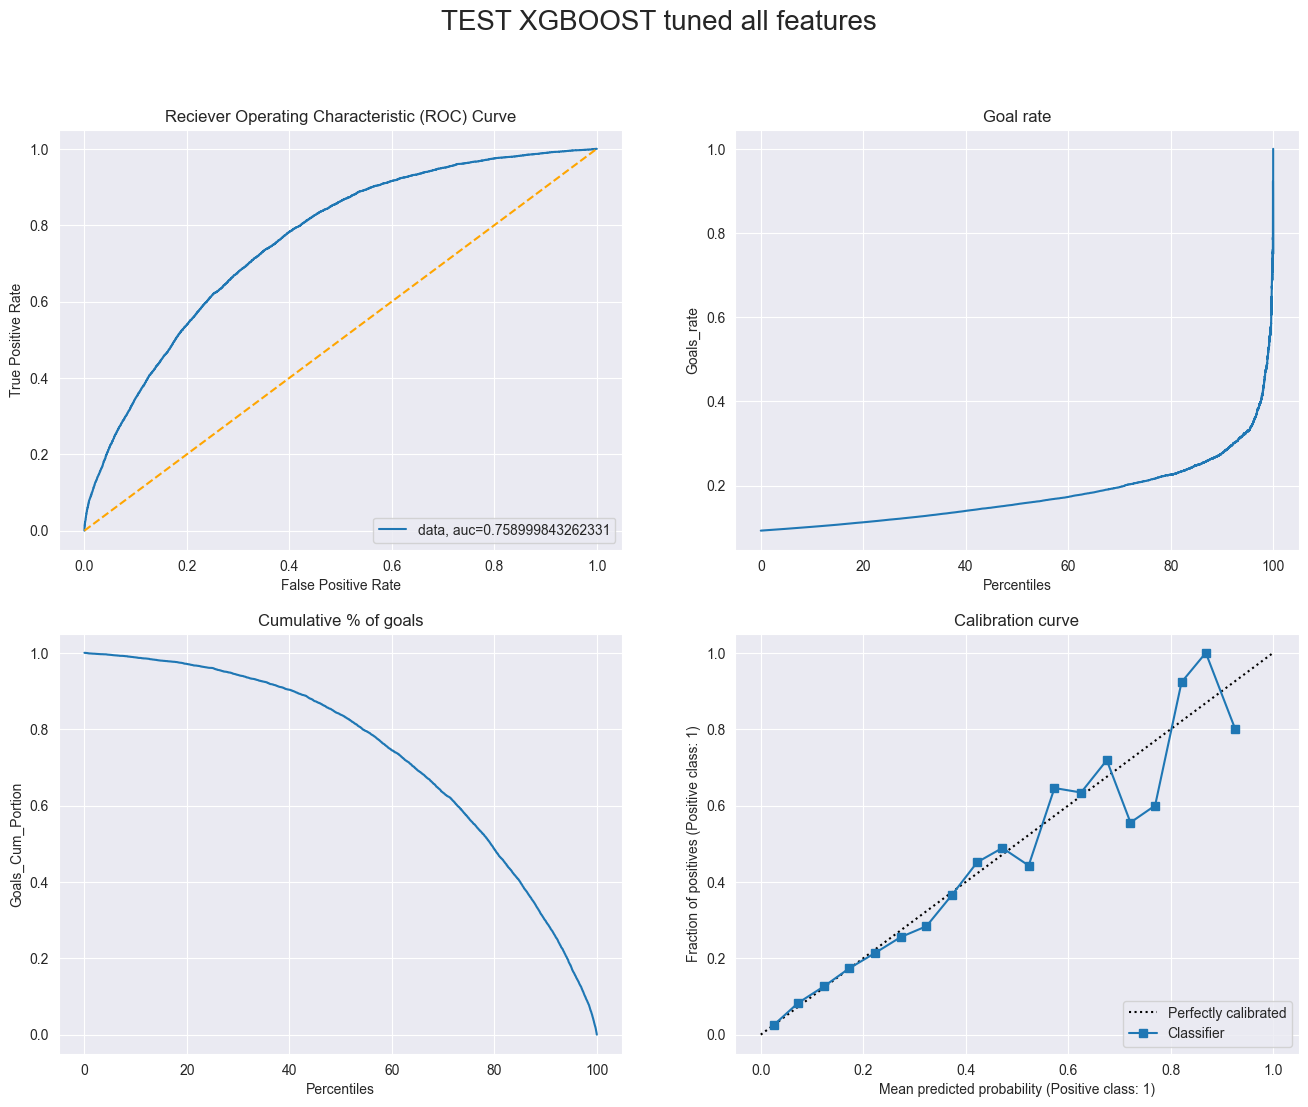

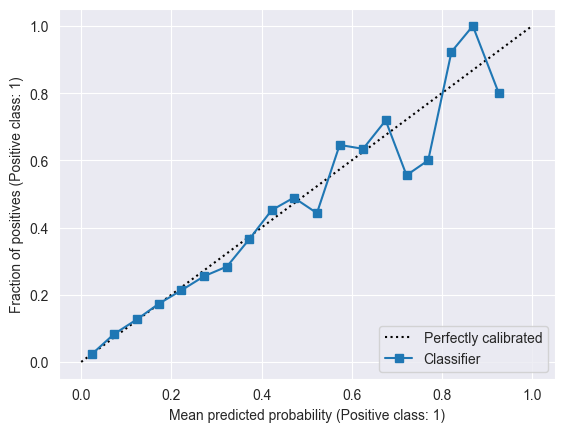

In [36]:
result = model.score(X_all,y_all)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST XGBOOST tuned all features", y_all, model.predict_proba(X_all)[:,1], 20)
f1 = metrics.f1_score(y_all, model.predict(X_all), average='macro')
ece = -my_calibration_scorer(model, X_all, y_all)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_all, model.predict_proba(X_all)[:,1])

Best model in Part 6, XGBOOST with selected features and tuned on ECE

In [37]:
model = XGBClassifier()
model.load_model("models/xgb_tuned_on_ece.json")

Accuracy on testing data:  90.77
f1 score: 0.49397048995274145
 ece: 0.003791584548033933


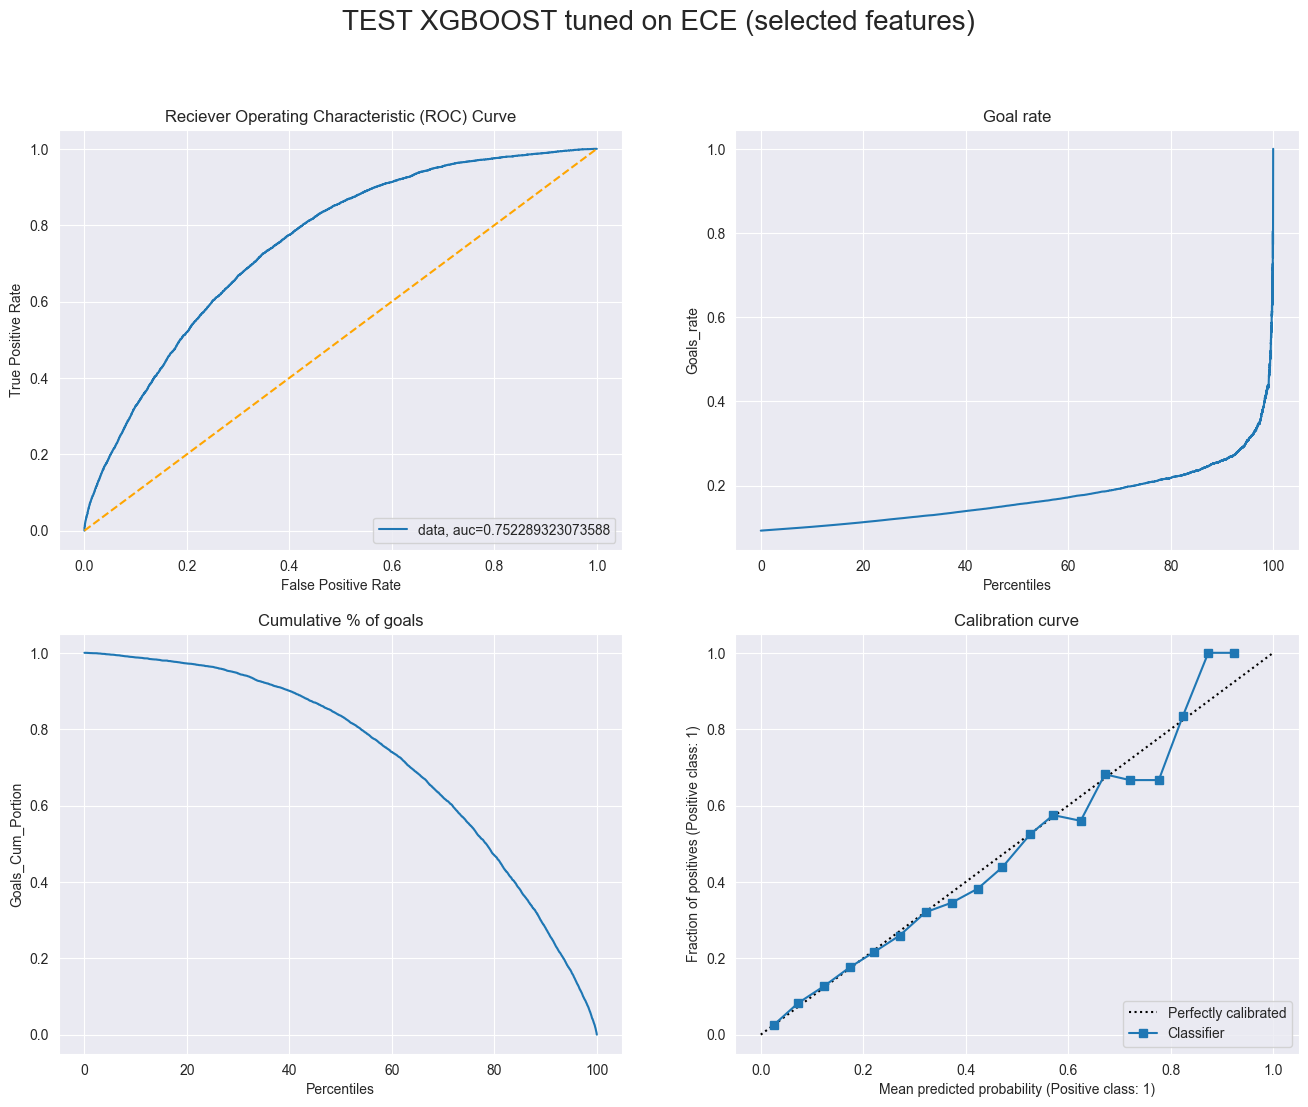

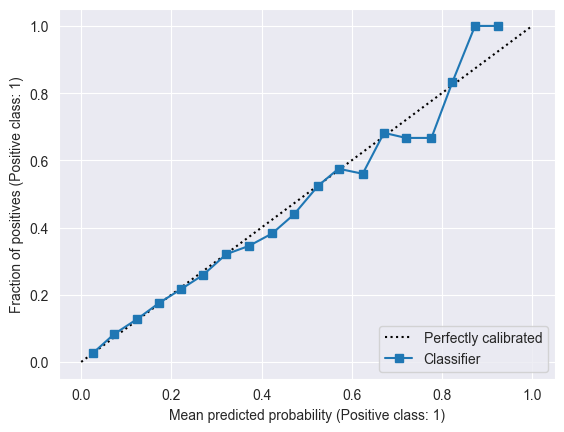

In [38]:
result = model.score(X_selected,y_selected)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST XGBOOST tuned on ECE (selected features)", y_selected, model.predict_proba(X_selected)[:,1], 20)
f1 = metrics.f1_score(y_selected, model.predict(X_selected), average='macro')
ece = -my_calibration_scorer(model, X_selected, y_selected)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_selected, model.predict_proba(X_selected)[:,1])

### Testing on playoffs

Data preprocessing

In [39]:
data = generate(seasons=[2019], play_offs=[True])

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2019-2020


In [40]:
df = engineered_data_frame(data)

In [42]:
selected_features = ["Period", "Period_Time_Seconds", "Distance_Net", "Angle", "X_Coordinate", "Speed",
                     "Friendly_Non_Goalies", "Opponent_Non_Goalies", "Shoot_Type"]
df_selected_features = df[selected_features]
df_selected_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)
df_selected_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7403 entries, 0 to 7402
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Period                7403 non-null   int64  
 1   Period_Time_Seconds   7403 non-null   int64  
 2   Distance_Net          7403 non-null   float64
 3   Angle                 7403 non-null   float64
 4   X_Coordinate          7403 non-null   float64
 5   Speed                 7266 non-null   float64
 6   Friendly_Non_Goalies  7403 non-null   int64  
 7   Opponent_Non_Goalies  7403 non-null   int64  
 8   Shoot_Type            7402 non-null   object 
 9   is_goal               7403 non-null   int64  
dtypes: float64(4), int64(5), object(1)
memory usage: 578.5+ KB


/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_28246/2249981398.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_selected_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)


In [43]:
df_selected_features = df_selected_features.dropna()
df_selected_features = df_selected_features[df_selected_features.Speed!=np.inf]

In [44]:
#On doit utiliser le même transformateur que celui qui a été utilisé pour les données d'entrainement (mêmes encodages,
#mêmes moyennes et déviations standard pour la standardisation).
my_transformer = joblib.load("models/selected_features_transformer.joblib")
X_selected = df_selected_features.iloc[:, :-1]
y_selected = df_selected_features.iloc[:, -1]
X_selected = my_transformer.transform(X_selected)
y_selected.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period', 'standard__Period_Time_Seconds',
       'standard__Distance_Net', 'standard__Angle',
       'standard__X_Coordinate', 'standard__Speed',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'remainder__Friendly_Non_Goalies',
       'remainder__Opponent_Non_Goalies'], dtype=object)

In [46]:
features_columns = ['Period_Time_Seconds', 'Period', 'X_Coordinate', 'Y_Coordinate', 'Distance_Net', 'Angle',
                    'Shoot_Type', 'Last_Event_Type', 'Last_Coordinate_X', 'Last_Coordinate_Y',
                    'Time_Between_Events', 'Distance_Last_Event', 'Rebond', 'Delta_Angle', 'Speed',
                    'Powerplay_Since', 'Friendly_Non_Goalies','Opponent_Non_Goalies']

In [47]:
df_all_features = df[features_columns]
df_all_features["is_goal"] = df["Event_Type"].map(lambda x: 1 if x == "Goal" else 0)
df_all_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7403 entries, 0 to 7402
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Period_Time_Seconds   7403 non-null   int64  
 1   Period                7403 non-null   int64  
 2   X_Coordinate          7403 non-null   float64
 3   Y_Coordinate          7403 non-null   float64
 4   Distance_Net          7403 non-null   float64
 5   Angle                 7403 non-null   float64
 6   Shoot_Type            7402 non-null   object 
 7   Last_Event_Type       7403 non-null   object 
 8   Last_Coordinate_X     7266 non-null   float64
 9   Last_Coordinate_Y     7266 non-null   float64
 10  Time_Between_Events   7403 non-null   int64  
 11  Distance_Last_Event   7266 non-null   float64
 12  Rebond                7403 non-null   bool   
 13  Delta_Angle           7403 non-null   float64
 14  Speed                 7266 non-null   float64
 15  Powerplay_Since      

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_28246/126522627.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_all_features["is_goal"] = df["Event_Type"].map(lambda x: 1 if x == "Goal" else 0)


In [48]:
df_all_features = df_all_features.dropna()
df_all_features = df_all_features[df_all_features.Speed != np.inf]
#On doit utiliser le même transformateur que celui qui a été utilisé pour les données d'entrainement (mêmes encodages,
#mêmes moyennes et déviations standard pour la standardisation).
my_transformer = joblib.load("models/all_features_transformer.joblib")
X_all = df_all_features.iloc[:, :-1]
y_all = df_all_features.iloc[:, -1]
X_all = my_transformer.transform(X_all)
y_all.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period_Time_Seconds', 'standard__X_Coordinate',
       'standard__Y_Coordinate', 'standard__Distance_Net',
       'standard__Angle', 'standard__Last_Coordinate_X',
       'standard__Last_Coordinate_Y', 'standard__Time_Between_Events',
       'standard__Distance_Last_Event', 'standard__Delta_Angle',
       'standard__Speed', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'one-hot__Last_Event_Type_Blocked Shot',
       'one-hot__Last_Event_Type_Faceoff',
       'one-hot__Last_Event_Type_Giveaway',
       'one-hot__Last_Event_Type_Goal', 'one-hot__Last_Event_Type_Hit',
       'one-hot__Last_Event_Type_Missed Shot',
       'one-hot__Last_Event_Type_Penalty',
       'one-hot__Last_Event_Type_Shot',
       'one-hot__Last_Event_Type

Logistic regression on distance

In [50]:
model = joblib.load("models/log_reg_dist.joblib")

Accuracy on testing data:  91.46
f1 score: 0.4776883686905633
 ece: 0.08542684523884533


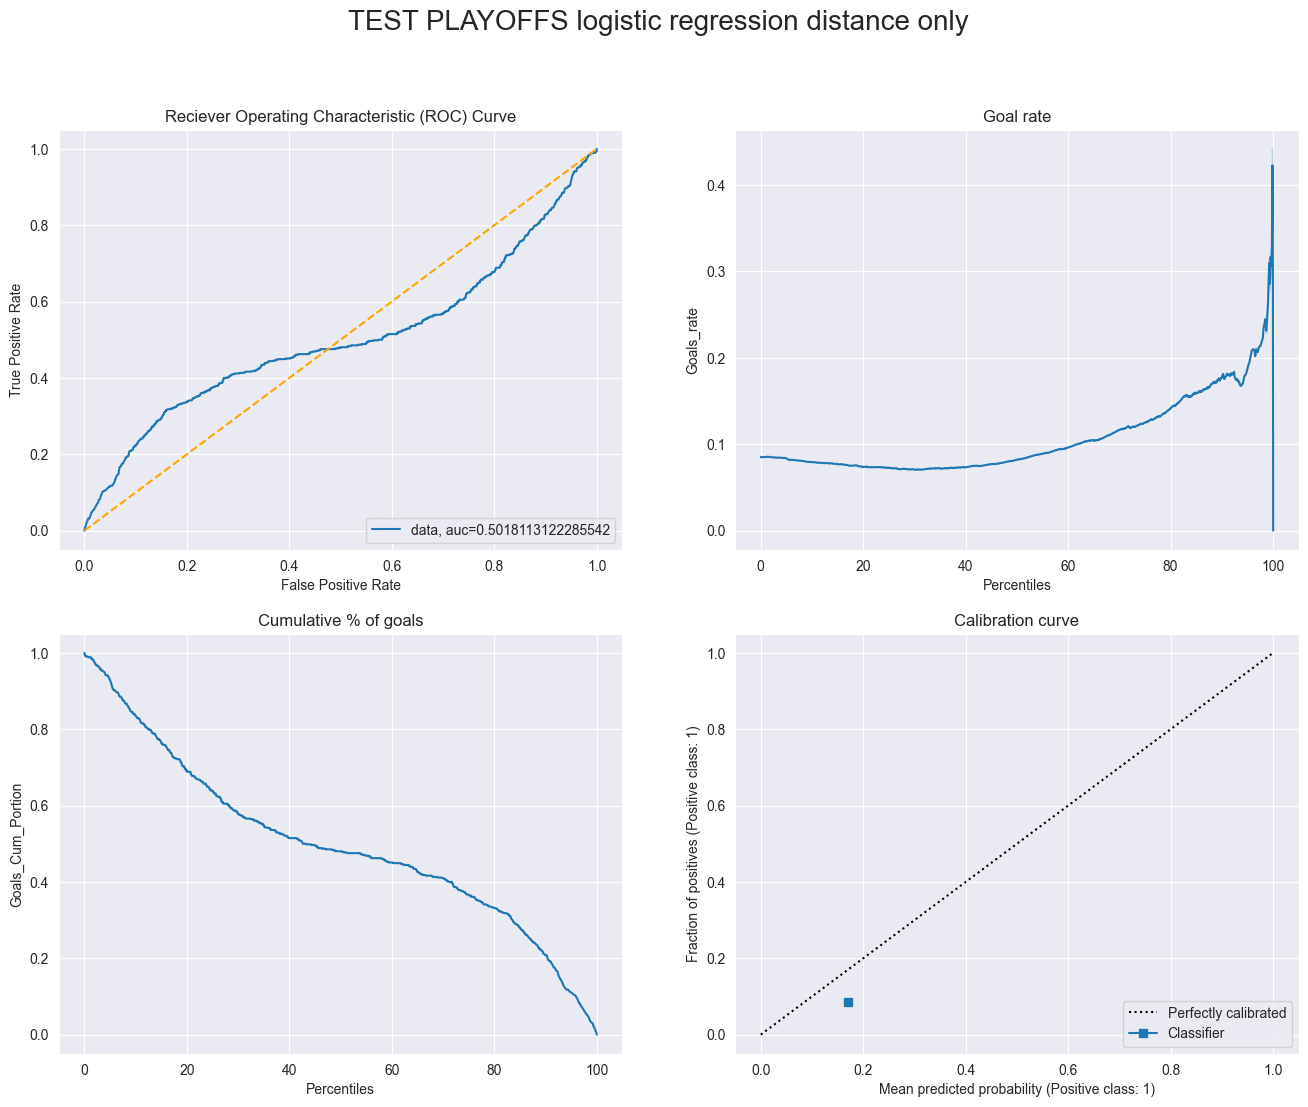

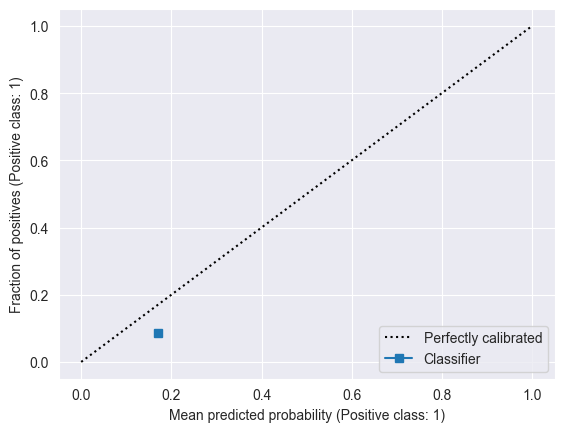

In [51]:
result = model.score(X_selected[:,2].reshape(-1,1),y_selected)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST PLAYOFFS logistic regression distance only", y_selected, model.predict_proba(X_selected[:,2].reshape(-1,1))[:,1], 20)
f1 = metrics.f1_score(y_selected, model.predict(X_selected[:,2].reshape(-1,1)), average='macro')
ece = -my_calibration_scorer(model, X_selected[:,2].reshape(-1,1), y_selected)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_selected, model.predict_proba(X_selected[:,2].reshape(-1,1))[:,1])

Logistic regression on angle

In [52]:
model = joblib.load("models/log_reg_angle.joblib")

Accuracy on testing data:  91.46
f1 score: 0.4776883686905633
 ece: 0.00820454009753277


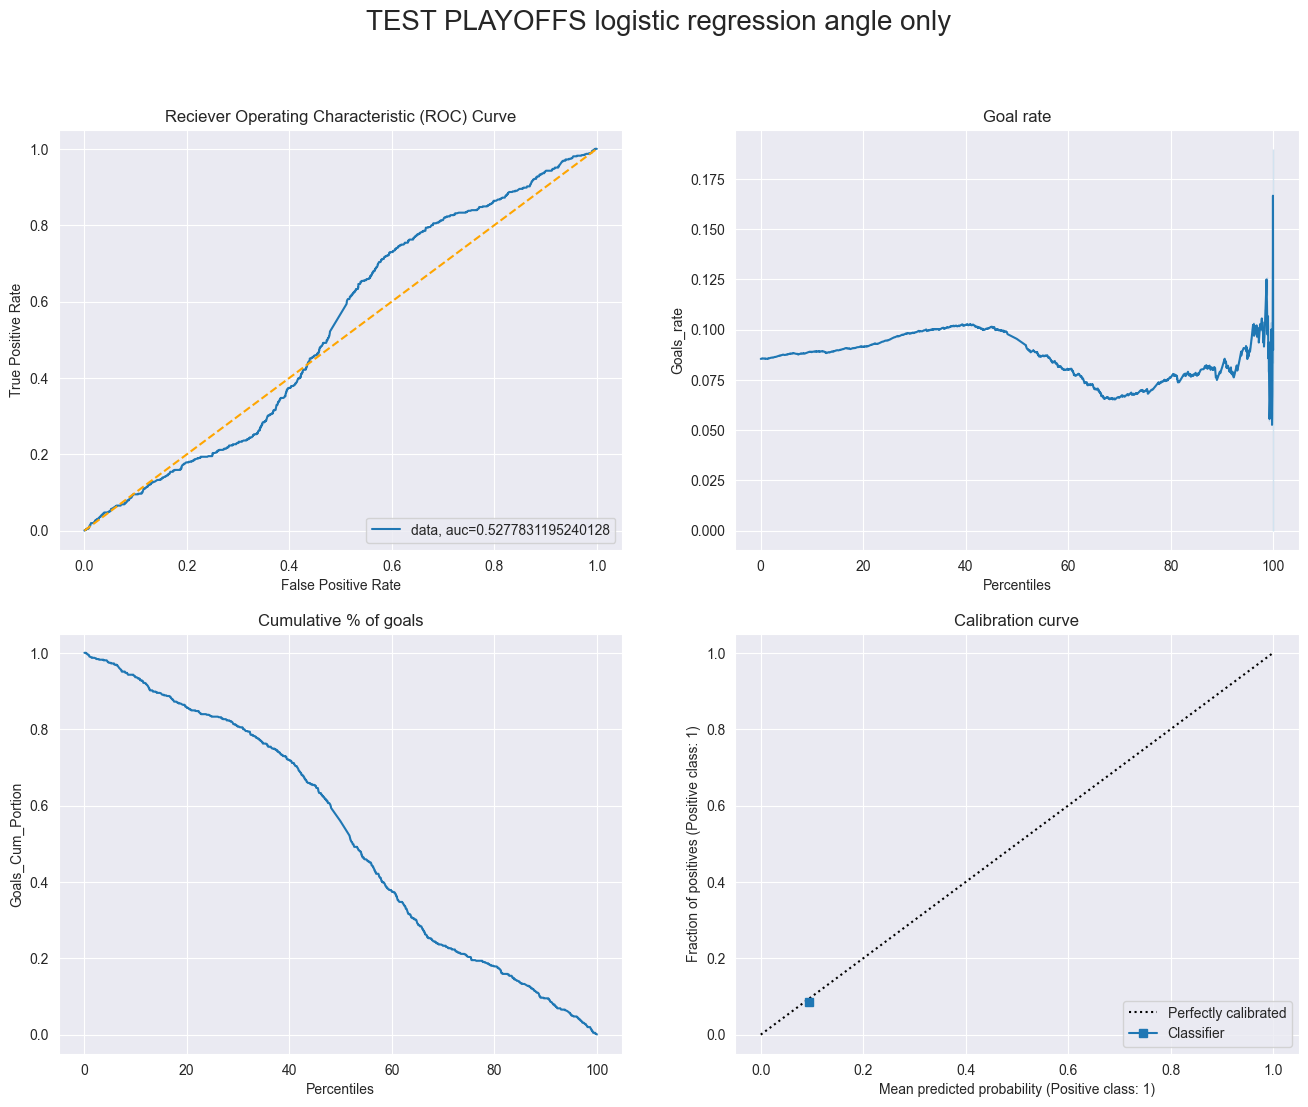

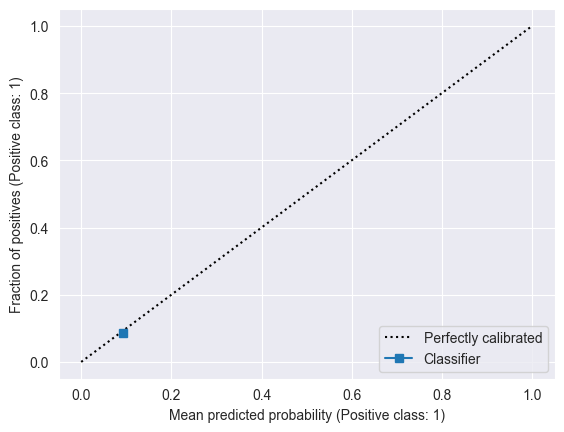

In [53]:
result = model.score(X_selected[:,3].reshape(-1,1),y_selected)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST PLAYOFFS logistic regression angle only", y_selected, model.predict_proba(X_selected[:,3].reshape(-1,1))[:,1], 20)
f1 = metrics.f1_score(y_selected, model.predict(X_selected[:,3].reshape(-1,1)), average='macro')
ece = -my_calibration_scorer(model, X_selected[:,3].reshape(-1,1), y_selected)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_selected, model.predict_proba(X_selected[:,3].reshape(-1,1))[:,1])

Logistic regression on angle and distance

In [54]:
model = joblib.load("models/log_reg_dist_and_angle.joblib")

Accuracy on testing data:  91.46
f1 score: 0.4776883686905633
 ece: 0.08551640448494335


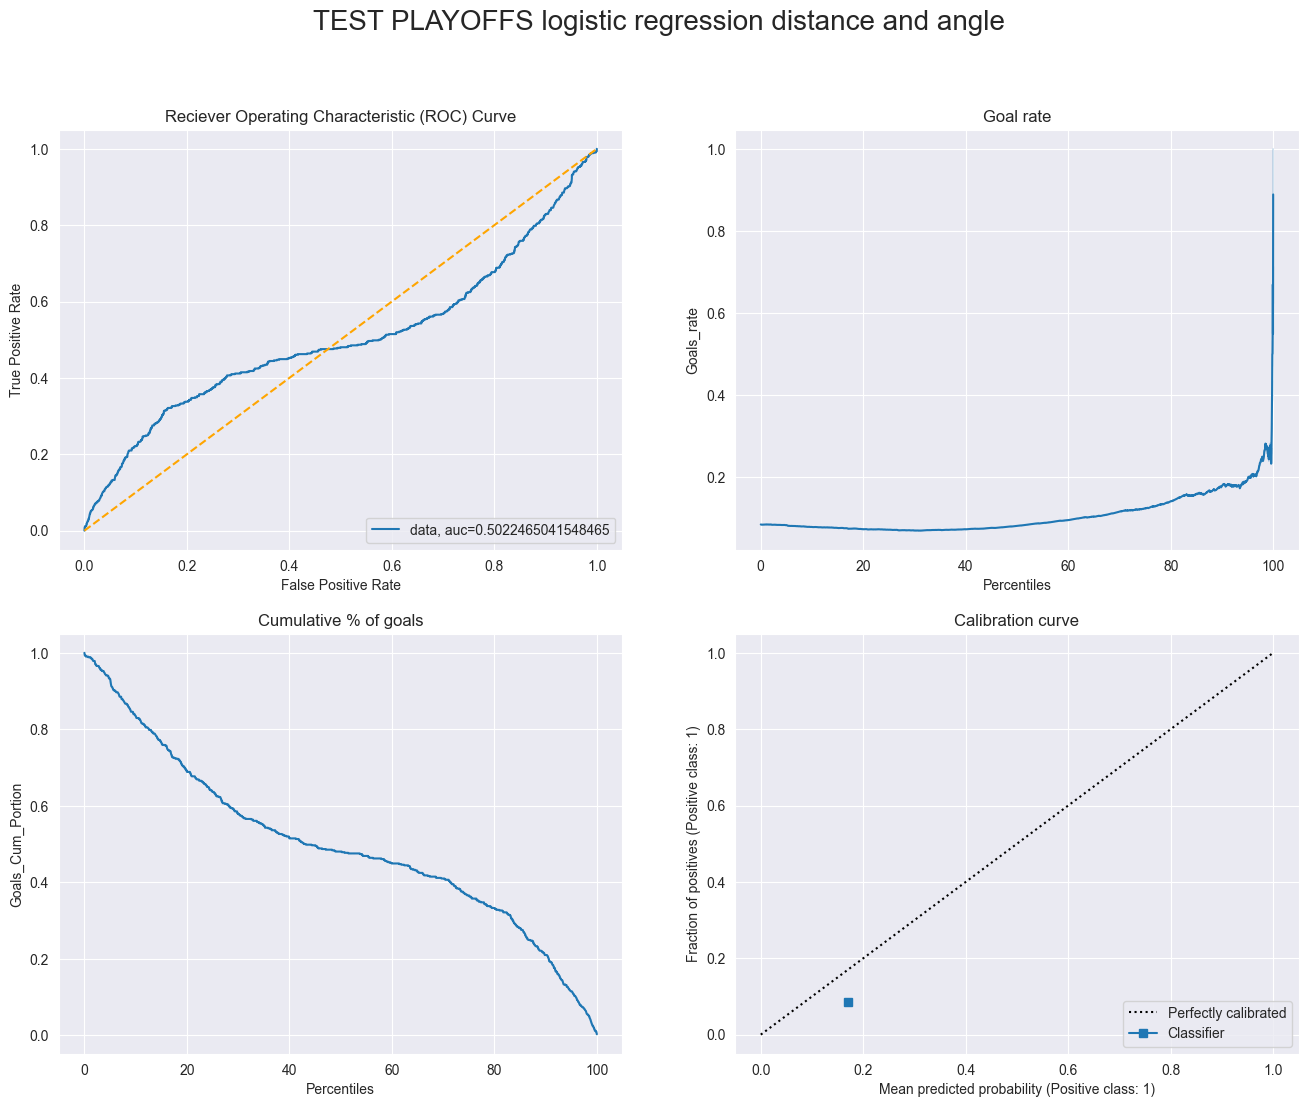

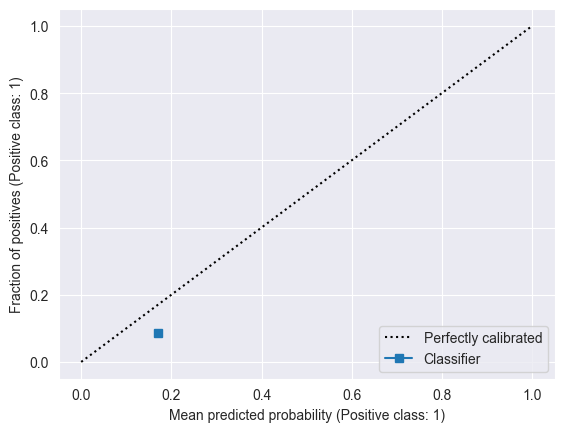

In [55]:
result = model.score(X_selected[:,2:4],y_selected)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST PLAYOFFS logistic regression distance and angle", y_selected, model.predict_proba(X_selected[:,2:4])[:,1], 20)
f1 = metrics.f1_score(y_selected, model.predict(X_selected[:,2:4]), average='macro')
ece = -my_calibration_scorer(model, X_selected[:,2:4], y_selected)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_selected, model.predict_proba(X_selected[:,2:4])[:,1])

Best XGBOOST model (Part 5, without feature selection)

In [56]:
from xgboost import XGBClassifier

In [57]:
model = XGBClassifier()
model.load_model("models/xgb_tuned_all_features.json")

Accuracy on testing data:  90.94
f1 score: 0.5011747754191566
 ece: 0.019884443838442466


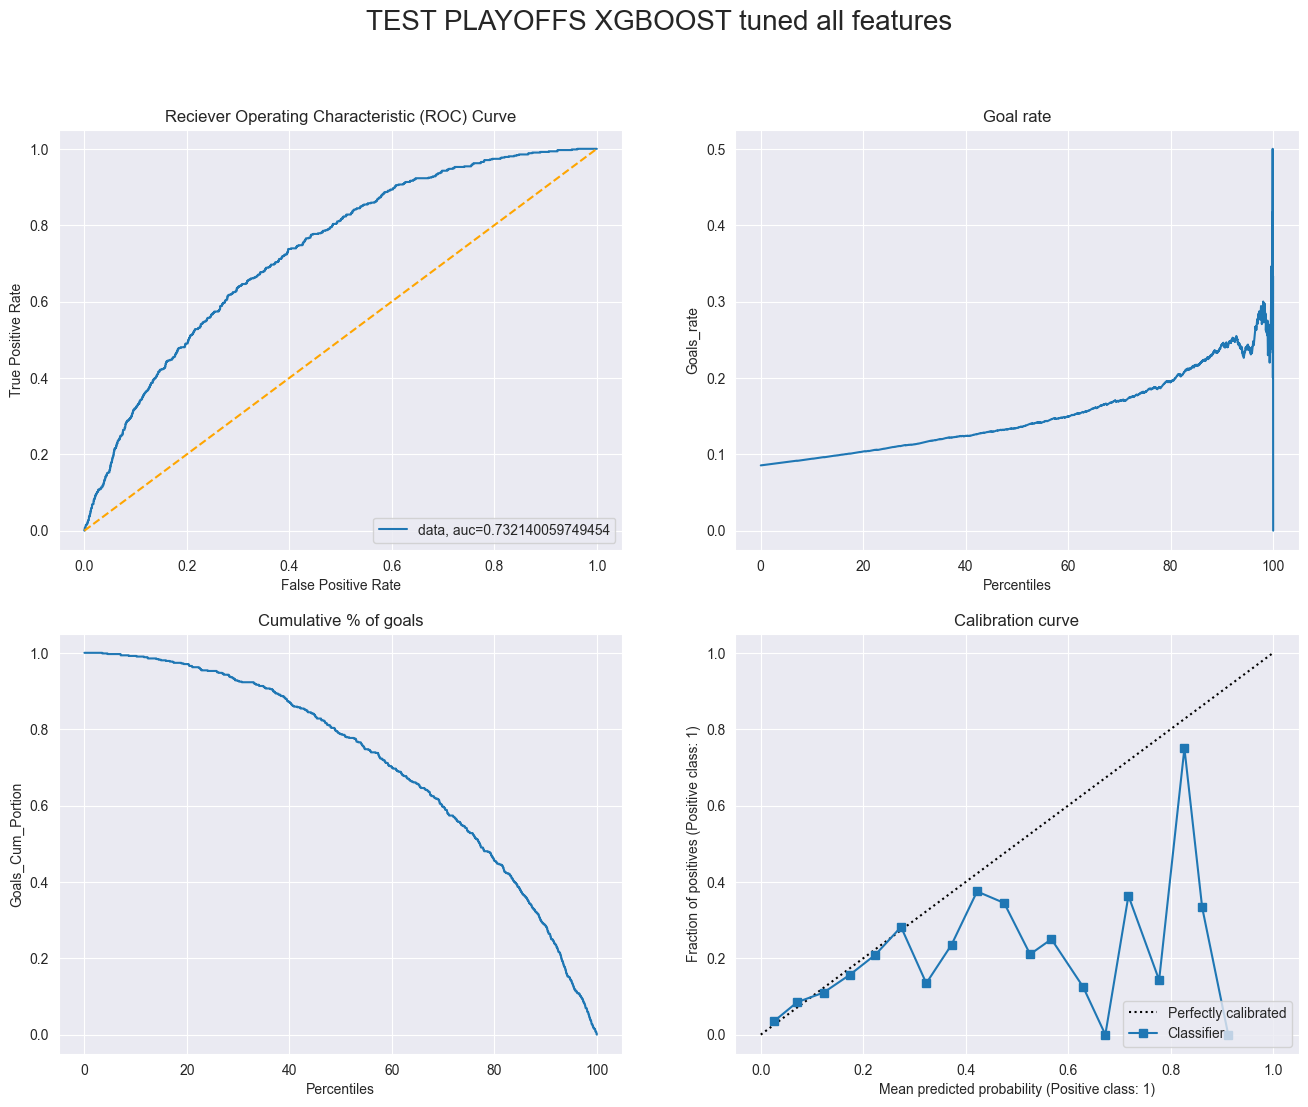

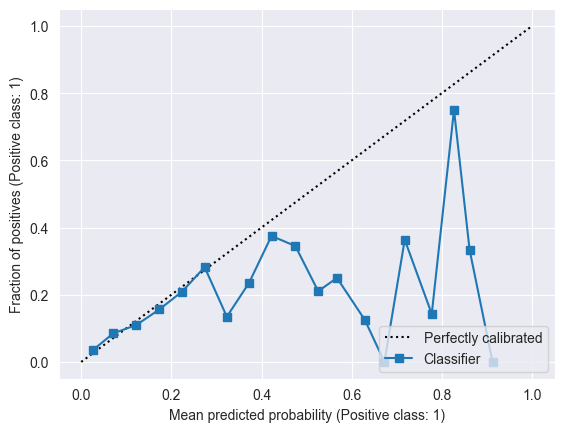

In [58]:
result = model.score(X_all,y_all)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST PLAYOFFS XGBOOST tuned all features", y_all, model.predict_proba(X_all)[:,1], 20)
f1 = metrics.f1_score(y_all, model.predict(X_all), average='macro')
ece = -my_calibration_scorer(model, X_all, y_all)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_all, model.predict_proba(X_all)[:,1])

Best model in Part 6, XGBOOST with selected features and tuned on ECE

In [59]:
model = XGBClassifier()
model.load_model("models/xgb_tuned_on_ece.json")

Accuracy on testing data:  91.02
f1 score: 0.5099005813742431
 ece: 0.022036578959093434


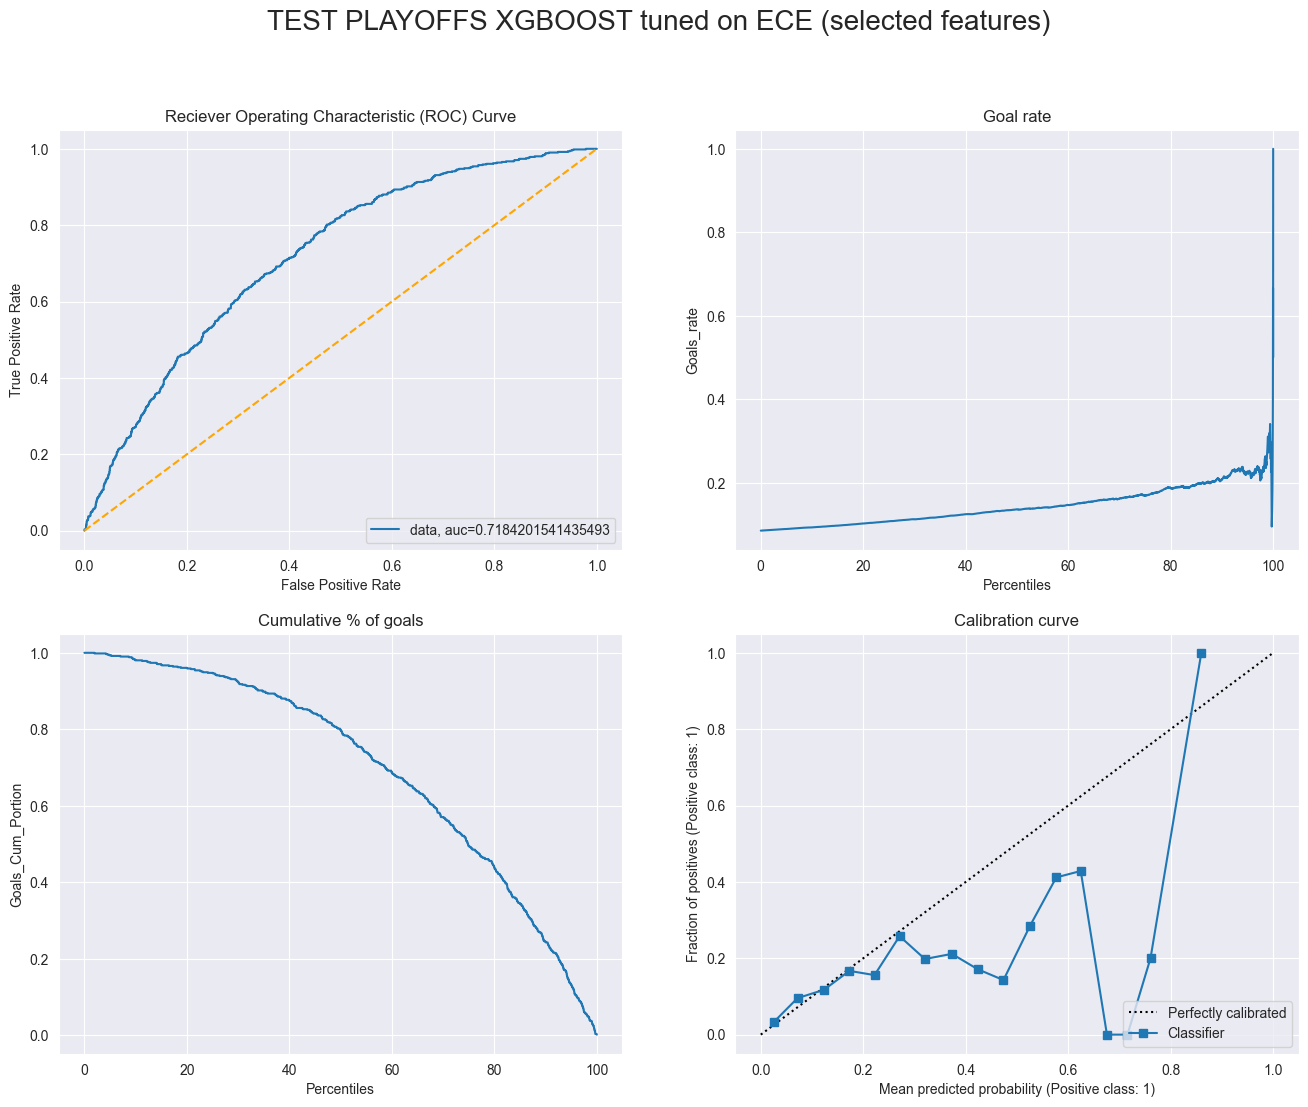

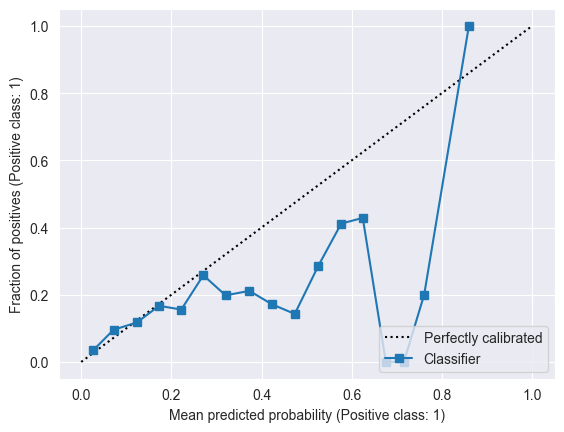

In [60]:
result = model.score(X_selected,y_selected)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("TEST PLAYOFFS XGBOOST tuned on ECE (selected features)", y_selected, model.predict_proba(X_selected)[:,1], 20)
f1 = metrics.f1_score(y_selected, model.predict(X_selected), average='macro')
ece = -my_calibration_scorer(model, X_selected, y_selected)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_selected, model.predict_proba(X_selected)[:,1])